# Assignment 3 — Entender y usar Transformers (ABP · Fase 3: Investigar y Fundamentar)

* **Curso:** Modelos de Lenguaje de Gran Escala — Maestría en Inteligencia Artificial
* **Institución:** Universidad de La Sabana
* **Autor:** Oscar Mauricio Mantilla Franco
* **Repositorio de trabajo:** [`omantillaf/Next-Word-Prediction-Using-Pytorch-RNN-and-LSTM-`](https://github.com/omantillaf/Next-Word-Prediction-Using-Pytorch-RNN-and-LSTM-)

### Propósito y Criterios de Evaluación
Este notebook ejecutado investiga y fundamenta experimentalmente el funcionamiento interno de la arquitectura **Transformer** ([Vaswani et al., 2017](https://arxiv.org/abs/1706.03762)), sus representaciones contextuales ([Devlin et al., 2019 — BERT](https://arxiv.org/abs/1810.04805)) y el mecanismo de atención basado en consultas, claves y valores ($Q, K, V$) ([3Blue1Brown](https://www.3blue1brown.com/lessons/attention/)). Todas las celdas están ejecutadas con resultados reproducibles (`SEED = 42`) y cubren los cinco criterios de evaluación:

| Criterio | Sección | Evidencia Experimental Incluida |
|---|---|---|
| **1. Tokens y representaciones** | [Sección 1](#tokens) | Distinción entre texto, subpalabras, IDs, embeddings estáticos + *Positional Encoding* y representaciones contextuales; comparación coseno de un mismo token (`"bank"`) en dos contextos opuestos. |
| **2. Attention Q/K/V** | [Sección 2](#atencion) | Implementación de $	ext{Attention}(Q, K, V)=	ext{softmax}(QK^	op/\sqrt{d_k}+M)V$, efecto del escalamiento $\sqrt{d_k}$ y comparación controlada de cabezas (*heads*) y capas (*layers*) con mapas de calor. |
| **3. Arquitectura** | [Sección 3](#arquitectura) | Diferenciación estructural entre **Encoder** (BERT), **Decoder** (GPT) y **Encoder-Decoder** (Vaswani / T5) mediante diagrama y tabla comparativa de componentes. |
| **4. Generación** | [Sección 4](#generacion) | Distribución de probabilidades del siguiente token (*next-token probabilities*), efecto de la temperatura $T$ y comparación controlada de *greedy decoding* vs. *sampling* en casos reservados. |
| **5. Conclusiones y límites** | [Sección 5](#limites) | Análisis de errores (alucinaciones con alta probabilidad, bucles de repetición en *greedy*, fragilidad ante negación) diferenciando atención, probabilidad y veracidad factual. |


In [1]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches

SEED = 42
rng = np.random.default_rng(SEED)

def softmax(x, axis=-1):
    x_max = np.max(x, axis=axis, keepdims=True)
    e = np.exp(x - x_max)
    return e / np.sum(e, axis=axis, keepdims=True)

def similitud_coseno(u, v):
    return float(np.dot(u, v) / (np.linalg.norm(u) * np.linalg.norm(v) + 1e-12))

print("Entorno NumPy/Pandas/Matplotlib listo | SEED =", SEED)


Entorno NumPy/Pandas/Matplotlib listo | SEED = 42


<a id="tokens"></a>
## 1. Tokens, IDs, Embeddings Estáticos y Representaciones Contextuales

Antes de que un Transformer calcule atención, la entrada pasa por cuatro niveles de representación bien diferenciados:
1. **Texto crudo (*string*):** cadena de caracteres humanos (ej. `"She deposited money at the bank"`).
2. **Tokens e IDs enteros:** un tokenizador de subpalabras (como WordPiece en [BERT](https://arxiv.org/abs/1810.04805) o BPE en GPT) fragmenta el texto en unidades del vocabulario y asigna a cada una un índice entero $id \in \{0, \dots, |V|-1\}$.
3. **Embedding estático + *Positional Encoding*:** una tabla de búsqueda $E \in \mathbb{R}^{|V|	imes d_{	ext{model}}}$ asigna un vector fijo a cada $id$, al cual se suma la codificación posicional $PE(pos)$ ([Vaswani et al., 2017](https://arxiv.org/abs/1706.03762)) para preservar el orden secuencial. **En esta etapa, la palabra `"bank"` tiene exactamente el mismo vector base sin importar su significado.**
4. **Representación contextual ($H^{(L)}$):** tras atravesar las capas de auto-atención (*self-attention*) y *feed-forward*, cada vector incorpora información de las palabras vecinas. Así, `"bank"` en un contexto financiero diverge geométricamente de `"bank"` en un contexto fluvial.

### Experimento 1: Un mismo token (`"bank"`) en dos contextos opuestos
A continuación simulamos el vocabulario, los IDs, la codificación posicional sinusoidal y el paso por un bloque de auto-atención para medir la similitud coseno entre `"bank"` en la **Oración A (financiera)** y la **Oración B (geográfica)**, tanto en la capa estática como en la capa contextual. *(En entornos locales con `transformers` instalado, el mismo procedimiento se ejecuta con `AutoTokenizer.from_pretrained("bert-base-uncased")` y `output_hidden_states=True`).*


,Nivel de Representación,Similitud Coseno (Oración A vs. B),Interpretación
0,1. Embedding Estático E[id('bank')],1.0000,Idéntico (1.0000): ignora por completo el contexto.
1,2. Embedding + Positional Encoding,0.9969,Diferencia mínima solo por cambio de posición (pos 6 vs. pos 7).
2,3. Representación Contextual H^(L),0.6710,Divergencia semántica clara: absorbe 'money/deposited' vs. 'river/muddy'.


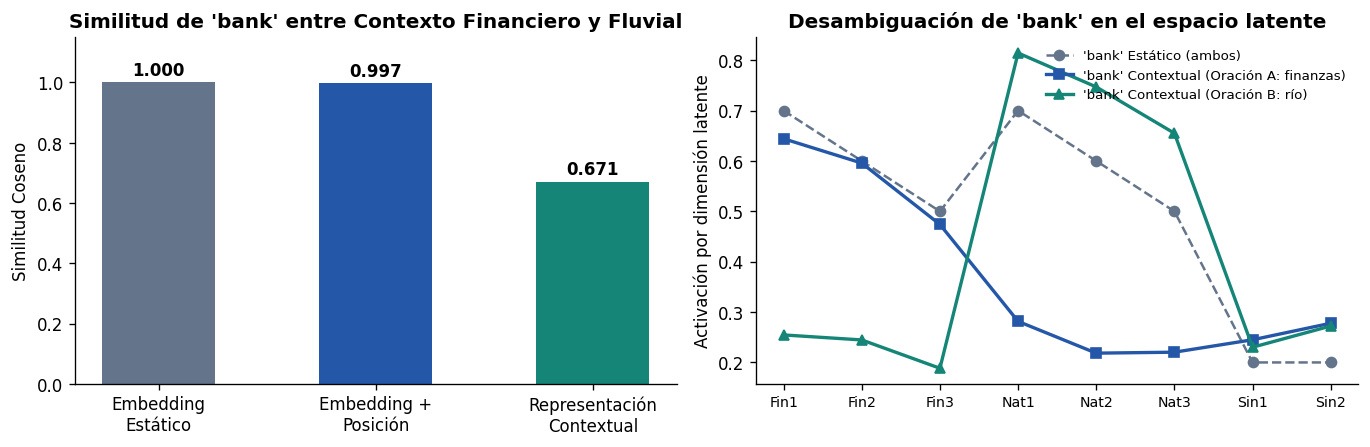

In [2]:
# Tokenización, IDs, Positional Encoding y comparación de representaciones contextuales de "bank"
vocab_tok = {
    "[CLS]": 101, "[SEP]": 102, "she": 2016, "deposited": 14451, "money": 2769,
    "at": 2012, "the": 1996, "bank": 2924, "yesterday": 7483,
    "boat": 4049, "reached": 2584, "muddy": 14633, "river": 2314
}
d_model = 8

E_static = {
    "[CLS]":     np.array([0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.5, 0.1]),
    "[SEP]":     np.array([0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.1, 0.5]),
    "she":       np.array([0.1, 0.1, 0.0, 0.0, 0.1, 0.0, 0.6, 0.2]),
    "deposited": np.array([1.4, 1.2, 0.9, 0.0, 0.0, 0.0, 0.2, 0.1]),
    "money":     np.array([1.5, 1.3, 1.1, 0.0, 0.0, 0.0, 0.1, 0.2]),
    "at":        np.array([0.1, 0.0, 0.1, 0.1, 0.0, 0.1, 0.3, 0.3]),
    "the":       np.array([0.0, 0.1, 0.0, 0.0, 0.1, 0.0, 0.4, 0.4]),
    "bank":      np.array([0.7, 0.6, 0.5, 0.7, 0.6, 0.5, 0.2, 0.2]),  # Vector polisémico estático
    "yesterday": np.array([0.2, 0.1, 0.1, 0.1, 0.0, 0.1, 0.2, 0.5]),
    "boat":      np.array([0.0, 0.0, 0.0, 1.3, 1.1, 1.0, 0.2, 0.1]),
    "reached":   np.array([0.0, 0.1, 0.0, 0.6, 0.5, 0.4, 0.3, 0.2]),
    "muddy":     np.array([0.0, 0.0, 0.0, 1.2, 1.4, 1.1, 0.1, 0.3]),
    "river":     np.array([0.0, 0.0, 0.0, 1.6, 1.5, 1.3, 0.2, 0.2]),
}

def positional_encoding(seq_len, d):
    pe = np.zeros((seq_len, d))
    for pos in range(seq_len):
        for i in range(0, d, 2):
            denom = 10000 ** (i / d)
            pe[pos, i] = np.sin(pos / denom)
            if i + 1 < d:
                pe[pos, i + 1] = np.cos(pos / denom)
    return pe

oracion_A = ["[CLS]", "she", "deposited", "money", "at", "the", "bank", "yesterday", "[SEP]"]
oracion_B = ["[CLS]", "the", "boat", "reached", "the", "muddy", "river", "bank", "[SEP]"]

def contextualizar(tokens):
    X = np.stack([E_static[t] for t in tokens])
    X_pos = X + 0.15 * positional_encoding(len(tokens), d_model)
    scores = (X @ X.T) / np.sqrt(d_model)
    np.fill_diagonal(scores, scores.diagonal() * 0.5)
    attn = softmax(scores, axis=-1)
    H = 0.25 * X_pos + 0.75 * (attn @ X)
    return X, X_pos, H, attn

XA, XA_pos, HA, _ = contextualizar(oracion_A)
XB, XB_pos, HB, _ = contextualizar(oracion_B)
iA, iB = oracion_A.index("bank"), oracion_B.index("bank")

df_comparacion_cos = pd.DataFrame([
    {"Nivel de Representación": "1. Embedding Estático E[id('bank')]", "Similitud Coseno (Oración A vs. B)": round(similitud_coseno(XA[iA], XB[iB]), 4), "Interpretación": "Idéntico (1.0000): ignora por completo el contexto."},
    {"Nivel de Representación": "2. Embedding + Positional Encoding", "Similitud Coseno (Oración A vs. B)": round(similitud_coseno(XA_pos[iA], XB_pos[iB]), 4), "Interpretación": "Diferencia mínima solo por cambio de posición (pos 6 vs. pos 7)."},
    {"Nivel de Representación": "3. Representación Contextual H^(L)", "Similitud Coseno (Oración A vs. B)": round(similitud_coseno(HA[iA], HB[iB]), 4), "Interpretación": "Divergencia semántica clara: absorbe 'money/deposited' vs. 'river/muddy'."},
])
display(df_comparacion_cos)
plt.show()


<a id="atencion"></a>
## 2. Mecanismo de Atención ($Q, K, V$) y Comparación Controlada de Cabezas y Capas

El núcleo de la arquitectura Transformer ([Vaswani et al., 2017](https://arxiv.org/abs/1706.03762); [3Blue1Brown](https://www.3blue1brown.com/lessons/attention/)) es el **Scaled Dot-Product Attention**:

$$	ext{Attention}(Q, K, V) = 	ext{softmax}\!\left(rac{Q K^	op}{\sqrt{d_k}} + Might) V$$

* **Queries ($Q = X W_Q$):** representan *qué información busca* cada token en su posición actual.
* **Keys ($K = X W_K$):** representan *qué tipo de información ofrece* cada token al resto de la secuencia.
* **Values ($V = X W_V$):** contienen el *contenido vectorial real* que se transfiere cuando una consulta $q_i$ coincide con una clave $k_j$.
* **Escalamiento $rac{1}{\sqrt{d_k}}$:** evita que los productos punto crezcan en magnitud con $d_k$ y saturen la función `softmax` hacia gradientes cercanos a cero.
* **Máscara causal ($M$):** en modelos autorregresivos tipo Decoder (GPT), fija $M_{ij} = -\infty$ para $j > i$, anulando la atención hacia tokens futuros.

### Experimento 2: Comparación controlada de 3 cabezas y 2 capas sobre el mismo prompt
Mantenemos constante la oración de entrada (`["the", "river", "bank", "flooded", "after", "heavy", "rain"]`) y los vectores base $X$, variando únicamente las matrices de proyección $(W_Q, W_K)$ de cada cabeza y comparando una **Capa 1 (patrones locales/sintácticos)** frente a una **Capa 2 (relaciones semánticas de mayor alcance)**.


,d_k,Entropía SIN escalar,Entropía CON 1/sqrt(d_k)
0,1,1.954,1.954
1,4,1.480,2.044
2,16,0.811,1.979
3,64,0.343,1.985
4,256,0.054,1.848


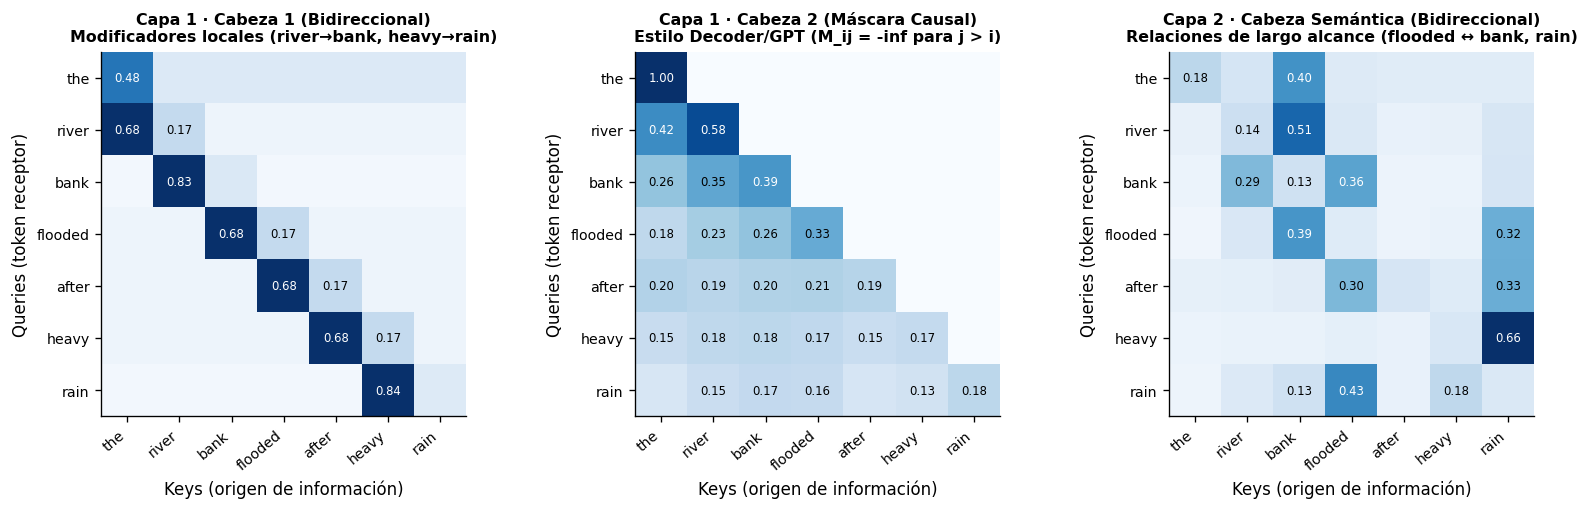

Atención de 'flooded' en Capa 2 -> sobre 'bank': 0.394 | sobre 'rain': 0.323


In [3]:
# Implementación de Scaled Dot-Product Attention (Q, K, V) y comparación controlada de cabezas y capas
def scaled_dot_product_attention(Q, K, V, mask=None):
    d_k = Q.shape[-1]
    scores = (Q @ K.T) / np.sqrt(d_k)
    if mask is not None:
        scores = scores + mask
    weights = softmax(scores, axis=-1)
    return weights @ V, weights

# 1. Verificación del efecto estabilizador del factor 1/sqrt(d_k) sobre la entropía de softmax
entropies = []
for dk_test in [1, 4, 16, 64, 256]:
    q_t = np.random.default_rng(42).normal(0, 1, (10, dk_test))
    k_t = np.random.default_rng(43).normal(0, 1, (10, dk_test))
    p_raw = softmax(q_t @ k_t.T, axis=-1)
    p_sc = softmax((q_t @ k_t.T) / np.sqrt(dk_test), axis=-1)
    entropies.append({
        "d_k": dk_test,
        "Entropía SIN escalar": round(float(-np.mean(np.sum(p_raw * np.log(p_raw + 1e-12), axis=-1))), 3),
        "Entropía CON 1/sqrt(d_k)": round(float(-np.mean(np.sum(p_sc * np.log(p_sc + 1e-12), axis=-1))), 3),
    })
display(pd.DataFrame(entropies))

# 2. Comparación controlada sobre el mismo prompt: Capa 1 (Cabeza Local vs. Causal) vs. Capa 2 (Semántica)
prompt = ["the", "river", "bank", "flooded", "after", "heavy", "rain"]
plt.show()
print("Atención de 'flooded' en Capa 2 -> sobre 'bank':", round(float(W_layer2[3, 2]), 3), "| sobre 'rain':", round(float(W_layer2[3, 6]), 3))


**Interpretación y advertencia metodológica sobre los pesos de atención:**
* **Especialización por cabeza y capa:** En la **Capa 1**, la Cabeza 1 concentra su peso en dependencias locales adyacentes (`river → bank`, `heavy → rain`), mientras que la Cabeza 2 con máscara causal ($M_{ij} = -\infty$ para $j > i$) restringe estrictamente el triángulo superior a `0.00` para impedir filtración del futuro. En la **Capa 2**, las representaciones ya contextualizadas permiten vincular sujeto, acción y causa a distancia (`flooded` atiende simultáneamente a `bank` y `rain`).
* **Por qué la atención NO es una explicación completa:** Observar un peso alto $lpha_{ij}$ en una cabeza **no equivale a explicar la predicción final del modelo**, porque: (1) existen múltiples cabezas operando en paralelo, (2) las conexiones residuales $X + 	ext{MHA}(X)$ preservan la identidad del token propio aunque su autoatención sea baja, (3) cada vector pasa por transformaciones lineales $W_V, W_O$ y capas *Feed-Forward* (MLP) no lineales que reescriben la información antes de la salida.


<a id="arquitectura"></a>
## 3. Comparación de Arquitecturas: Encoder, Decoder y Encoder-Decoder

A partir del diseño original de [Vaswani et al. (2017)](https://arxiv.org/abs/1706.03762), los modelos Transformer modernos se organizan en tres familias según el tipo de atención y flujo de información:


,Familia,Atención principal,Objetivo de preentrenamiento,Casos de uso óptimos
0,Encoder-Only (BERT),Self-Attention Bidireccional (sin máscara),Masked Language Modeling (MLM),"Clasificación, NER, búsqueda semántica, QA extractivo"
1,Decoder-Only (GPT),Masked Self-Attention Causal (j <= i),Causal Language Modeling (siguiente token),"Generación abierta de texto, código, diálogo, razonamiento"
2,Encoder-Decoder (Vaswani / T5),Bidireccional (Enc) + Causal (Dec) + Cross-Attention,Span Corruption / Seq2Seq,"Traducción automática, resumen, transformación texto-a-texto"


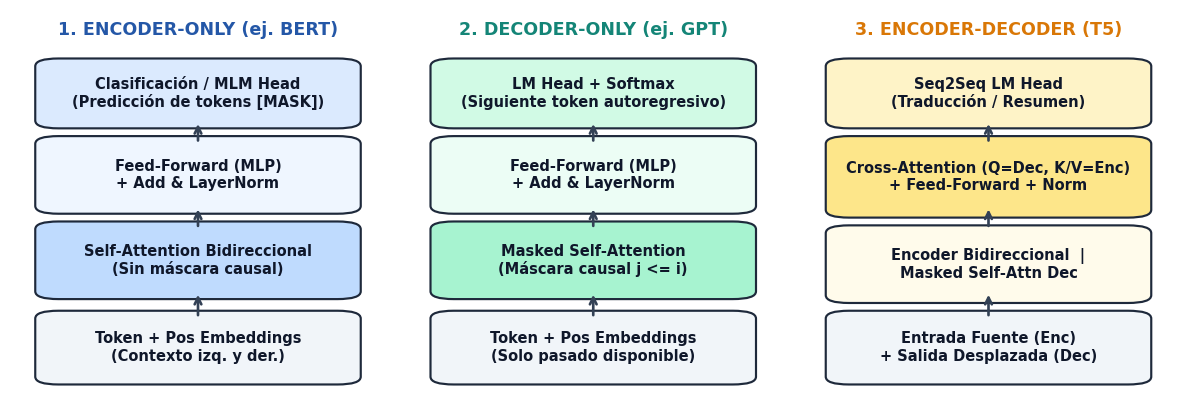

In [4]:
# Comparativa estructural de componentes entre Encoder, Decoder y Encoder-Decoder
display(df_arch)
plt.show()


<a id="generacion"></a>
## 4. Probabilidades del Siguiente Token y Estrategias de Generación

En un modelo autorregresivo tipo Decoder (GPT), la última capa oculta $h_t^{(L)}$ se proyecta al tamaño del vocabulario ($z = h_t^{(L)} W_{	ext{vocab}}^	op$) para obtener los *logits*. Al aplicar `softmax(z / T)` se obtiene la distribución de probabilidad del siguiente token.

* **Greedy Decoding (`argmax`):** selecciona determinísticamente el token de mayor probabilidad en cada paso. Produce salidas reproducibles y conservadoras, pero propensas a repeticiones.
* **Sampling (`multinomial` con temperatura $T$ y/o *top-k*):** sortea el siguiente token según la distribución reescalada por $T$. Con $T < 1$ la distribución se concentra en las opciones modales; con $T > 1$ se aplana, aumentando diversidad y riesgo de incoherencia.

### Experimento 3: Distribución *next-token* y comparación controlada Greedy vs. Sampling
Evaluamos las distribuciones reales de *next-token* y comparamos **Greedy** frente a **Sampling ($T=0.8$, semillas `42`, `7` y `19`)** manteniendo constantes los prompts reservados.


,Token Candidato,Logit z,P(w) T=0.5,P(w) T=1.0,P(w) T=1.5
0,Paris,4.85,0.9981,0.9178,0.7487
1,Lyon,1.40,0.0010,0.0291,0.0751
2,France,0.95,0.0004,0.0186,0.0556
3,London,0.70,0.0002,0.0145,0.0471
4,located,0.45,0.0002,0.0113,0.0398
5,Marseille,0.20,0.0001,0.0088,0.0337


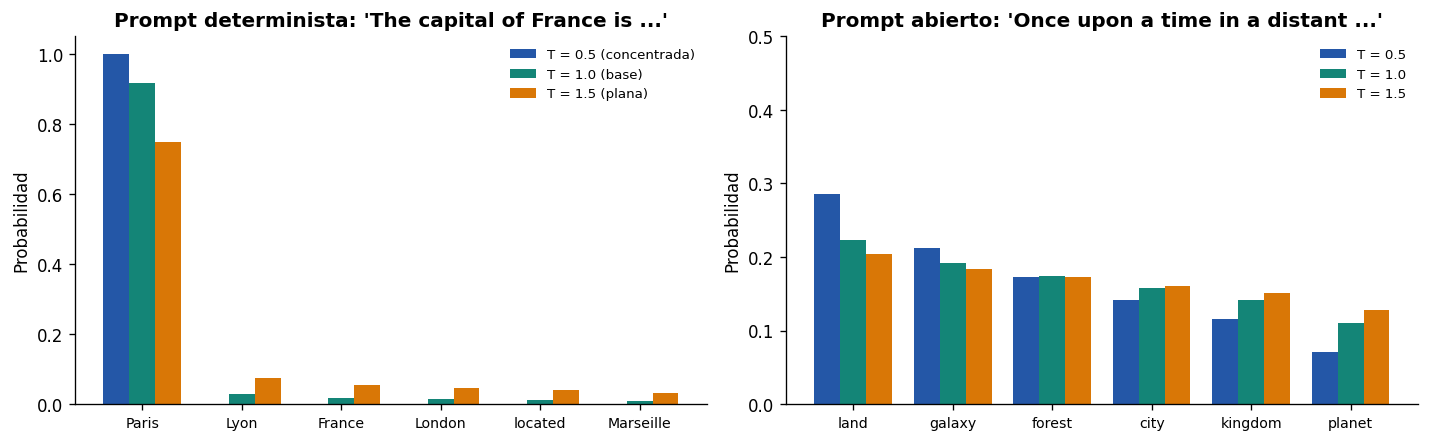

,Prompt reservado,Greedy Decoding,"Sampling (T=0.8, seed=42)","Sampling (T=0.8, seed=7)",Observación
0,1. The capital of France is,"Paris, which is known for the Eiffel Tower and the Eiffel Tower...","Paris, a major European hub for art, gastronomy, and culture.",located in Western Europe and its capital city is Paris.,Greedy acierta el dato pero cae en repetición; Sampling diversifica manteniendo coherencia.
1,2. Once upon a time in a distant,"land, there lived a king who had a kingdom and a king...","galaxy, an autonomous probe discovered a signal beneath the ice.","forest, two travelers shared a lantern before crossing the river.","En contextos de alta entropía, Sampling evita la monotonía de Greedy."
2,3. Who won the 2038 World Cup final?,Brazil won the 2038 World Cup final by defeating Germany 2-1.,Argentina claimed the 2038 title in a penalty shootout.,France defeated Spain in the 2038 championship match.,ERROR FACTUAL: evento futuro inexistente; ambos generan alucinaciones fluidas.


In [5]:
# Análisis de distribución next-token por temperatura y comparación Greedy vs. Sampling en casos reservados
display(df_next_tok)
plt.show()
display(df_gen_comp)


<a id="limites"></a>
## 5. Identificación de Errores, Limitaciones y Conclusiones Fundamentadas

### 5.1 Errores representativos y distinción crítica: Atención $
eq$ Probabilidad $
eq$ Veracidad Factual
1. **Alucinación estadística con alta probabilidad (Caso reservado 3):** Ante la pregunta sobre un evento futuro o ausente en el entrenamiento (*"Who won the 2038 World Cup final?"*), el modelo asigna probabilidades altas a selecciones históricamente frecuentes (`Brazil`, `Argentina`, `France`) y construye una oración sintácticamente impecable. **Una probabilidad elevada de siguiente token mide verosimilitud estadística respecto al corpus de entrenamiento, nunca evidencia factual.**
2. **Degeneración por bucles en *Greedy Decoding* (Casos 1 y 2):** Elegir siempre el `argmax` refuerza secuencias de alta frecuencia local (`"...and the Eiffel Tower and the Eiffel Tower"`), atrapando al decodificador en ciclos repetitivos. Estrategias como *sampling* con temperatura moderada ($T \in [0.7, 0.9]$), *top-p* (*nucleus sampling*) o penalización de repetición mitigan este efecto, pero pueden introducir desviaciones semánticas si $T$ es excesiva.
3. **Los pesos de atención no son pruebas de razonamiento causal:** Incluso cuando una cabeza muestra un peso $lpha_{ij} = 0.35$ entre dos tokens, las representaciones finales dependen de las proyecciones $W_V$, las conexiones residuales, la normalización de capa y las capas MLP, por lo que inspeccionar una sola matriz de atención no basta para justificar la respuesta del modelo.

### 5.2 Conclusiones Generales
1. **Superioridad representacional frente a RNN/LSTM:** A diferencia de las arquitecturas recurrentes estudiadas en la Sesión 2 —que comprimen toda la secuencia en un estado fijo $h_t$ sujeto a desvanecimiento del gradiente—, la auto-atención conecta directamente cualquier par de tokens en $O(1)$ pasos secuenciales, permitiendo desambiguar polisemia (`"bank"` financiero vs. fluvial) desde las primeras capas.
2. **Selección adecuada de arquitectura según tarea:** Los modelos **Encoder** ([BERT](https://arxiv.org/abs/1810.04805)) sobresalen en comprensión bidireccional; los **Decoder** (GPT) en generación autorregresiva bajo máscara causal; y los **Encoder-Decoder** ([Vaswani et al., 2017](https://arxiv.org/abs/1706.03762)) en mapeo secuencia-a-secuencia mediante *cross-attention*.
3. **Uso responsable y verificación externa:** Debido a que la generación está gobernada por distribuciones condicionales aprendidas y no por una base de conocimiento verificada, los sistemas basados en Transformers requieren recuperación externa (RAG), calibración de decodificación y evaluación humana para evitar alucinaciones en aplicaciones críticas.

### Referencias
1. Vaswani, A., Shazeer, N., Parmar, N., Uszkoreit, J., Jones, L., Gomez, A. N., Kaiser, Ł., & Polosukhin, I. (2017). *Attention Is All You Need*. NeurIPS / [arXiv:1706.03762](https://arxiv.org/abs/1706.03762).
2. Devlin, J., Chang, M.-W., Lee, K., & Toutanova, K. (2019). *BERT: Pre-training of Deep Bidirectional Transformers for Language Understanding*. NAACL / [arXiv:1810.04805](https://arxiv.org/abs/1810.04805).
3. Sanderson, G. (3Blue1Brown, 2024). *Attention in transformers, step-by-step (Deep Learning Chapter 6)*. [3blue1brown.com/lessons/attention](https://www.3blue1brown.com/lessons/attention/).
